In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip -q install rasterio geopandas matplotlib

Raster CRS: EPSG:32618
Raster bounds: BoundingBox(left=592371.56518, bottom=501705.04172000004, right=593606.62878, top=503768.46364000003)
Raster transform: | 0.04, 0.00, 592371.57|
| 0.00,-0.04, 503768.46|
| 0.00, 0.00, 1.00|
Original label CRS: EPSG:4326
Original label bounds: [-74.16683812   4.54000214 -74.15732584   4.55526623]
Reprojected label bounds: [592423.15006636 501870.98753989 593478.61267857 503558.83035432]


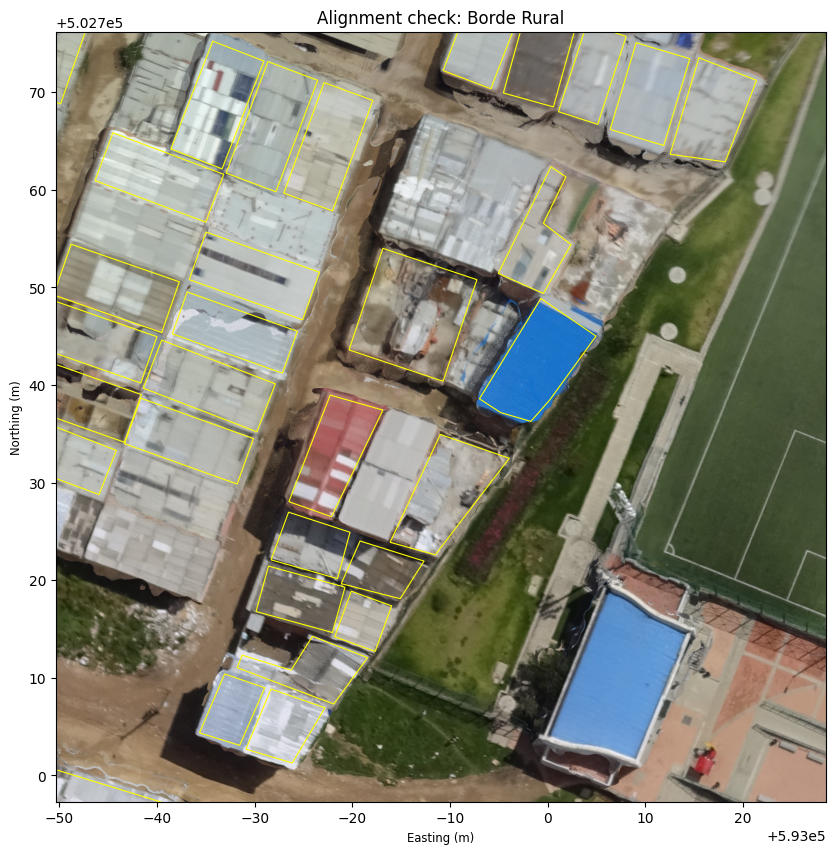

Footprints intersecting crop: 31


In [ ]:
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
from rasterio.windows import Window
from rasterio.plot import show
from shapely.geometry import box

folder = Path("/content/drive/MyDrive/RoofMaterialProject/borde_rural")

image_path = folder / "borde_rural_ortho-cog.tif"
labels_path = folder / "train-borde_rural.geojson"

buildings = gpd.read_file(labels_path)

with rasterio.open(image_path) as src:
    print("Raster CRS:", src.crs)
    print("Raster bounds:", src.bounds)
    print("Raster transform:", src.transform)
    print("Original label CRS:", buildings.crs)
    print("Original label bounds:", buildings.total_bounds)

    # Reproject labels into the raster's coordinate system
    buildings = buildings.to_crs(src.crs)
    print("Reprojected label bounds:", buildings.total_bounds)

    # Choose a crop around the center of the image
    window = Window(
        src.width // 2 - 1000,
        src.height // 2 - 1000,
        2000,
        2000
    )

    image = src.read([1, 2, 3], window=window)
    crop_transform = src.window_transform(window)

    left, bottom, right, top = rasterio.windows.bounds(window, src.transform)
    crop_box = box(left, bottom, right, top)

    # Select only footprints intersecting this crop
    visible = buildings[buildings.intersects(crop_box)]

    fig, ax = plt.subplots(figsize=(12, 10))

    # Let Rasterio position the crop using its actual geospatial transform
    show(image, transform=crop_transform, ax=ax)

    visible.boundary.plot(
        ax=ax,
        color="yellow",
        linewidth=0.8
    )

    ax.set_xlim(left, right)
    ax.set_ylim(bottom, top)
    ax.set_title("Alignment check: Borde Rural")
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    plt.show()

    print("Footprints intersecting crop:", len(visible))

In [ ]:
import rasterio
import geopandas as gpd
from pathlib import Path

folder = Path("/content/drive/MyDrive/RoofMaterialProject/borde_rural")

image_path = folder / "borde_rural_ortho-cog.tif"
labels_path = folder / "train-borde_rural.geojson"

with rasterio.open(image_path) as src:
    image_bounds = src.bounds
    image_crs = src.crs

buildings = gpd.read_file(labels_path).to_crs(image_crs)

from shapely.geometry import box
image_footprint = box(
    image_bounds.left,
    image_bounds.bottom,
    image_bounds.right,
    image_bounds.top
)

inside = buildings.geometry.within(image_footprint)
intersects = buildings.geometry.intersects(image_footprint)

print("Total training buildings:", len(buildings))
print("Completely inside image:", int(inside.sum()))
print("Intersecting image:", int(intersects.sum()))
print("Outside or touching image boundary:", int((~intersects).sum()))
print("\nRoof-material counts:")
print(buildings["roof_material"].value_counts())

Total training buildings: 4361
Completely inside image: 4361
Intersecting image: 4361
Outside or touching image boundary: 0

Roof-material counts:
roof_material
healthy_metal      2383
irregular_metal    1508
incomplete          245
concrete_cement     217
other                 8
Name: count, dtype: int64


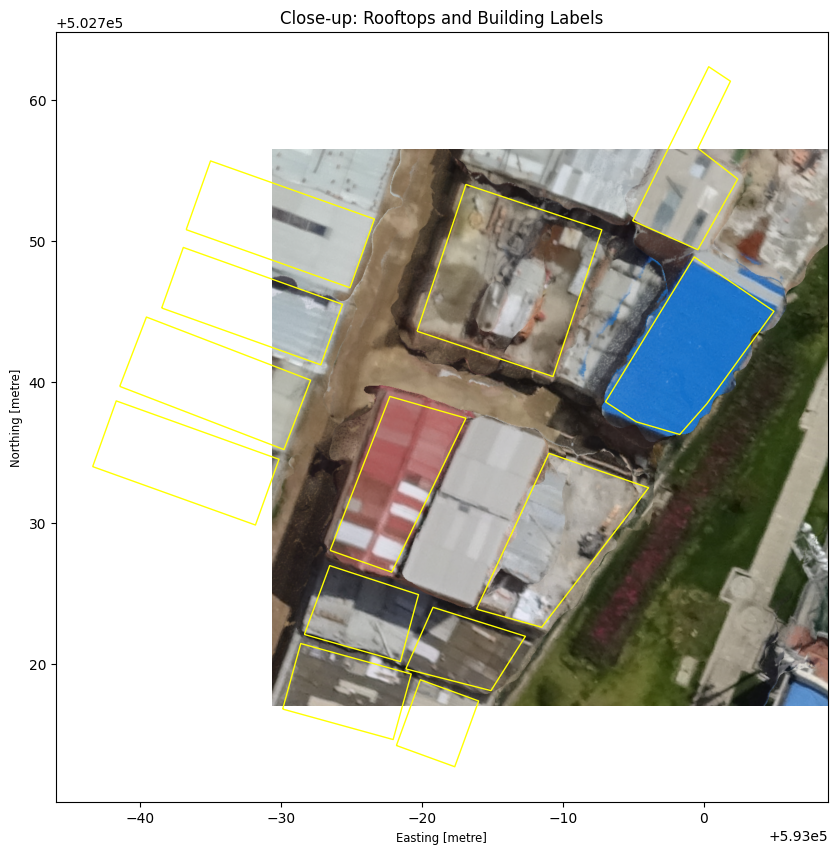

Buildings visible: 13


In [ ]:
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
from rasterio.windows import Window

folder = Path("/content/drive/MyDrive/RoofMaterialProject/borde_rural")
image_path = folder / "borde_rural_ortho-cog.tif"
labels_path = folder / "train-borde_rural.geojson"

buildings = gpd.read_file(labels_path)

with rasterio.open(image_path) as src:
    buildings = buildings.to_crs(src.crs)

    # Choose a crop around the centre of the image
    window = Window(
        src.width // 2 - 500,
        src.height // 2 - 500,
        1000,
        1000
    )

    image = src.read([1, 2, 3], window=window)
    bounds = rasterio.windows.bounds(window, src.transform)

    image = image.transpose(1, 2, 0)

    fig, ax = plt.subplots(figsize=(12, 10))
    ax.imshow(
        image,
        extent=[bounds[0], bounds[2], bounds[1], bounds[3]]
    )

    visible = buildings.cx[
        bounds[0]:bounds[2],
        bounds[1]:bounds[3]
    ]

    visible.boundary.plot(
        ax=ax,
        edgecolor="yellow",
        linewidth=1
    )

    ax.set_title("Close-up: Rooftops and Building Labels")
    plt.show()

    print("Buildings visible:", len(visible))

In [2]:
"""
import os
import rasterio
import geopandas as gpd
from shapely.geometry import box

# Borde Rural folder
folder = "/content/drive/MyDrive/RoofMaterialProject/borde_rural"

image_path = os.path.join(folder, "borde_rural_ortho-cog.tif")
train_path = os.path.join(folder, "train-borde_rural.geojson")
test_path = os.path.join(folder, "test-borde_rural.geojson")

# 1. Inspect aerial image metadata
with rasterio.open(image_path) as src:
    image_crs = src.crs
    image_bounds = src.bounds
    image_footprint = box(*image_bounds)

    print("=== AERIAL IMAGE ===")
    print("CRS:", image_crs)
    print("Dimensions (width x height):", src.width, "x", src.height)
    print("Band count:", src.count)
    print("Data type:", src.dtypes)
    print("Pixel resolution:", src.res)
    print("Bounds:", image_bounds)
    print("Coordinate units:", src.crs.linear_units
          if src.crs and src.crs.is_projected else "Geographic or unknown")

# 2. Inspect training and testing labels
for label_path, label_name in [
    (train_path, "TRAIN"),
    (test_path, "TEST")
]:
    gdf = gpd.read_file(label_path)

    print(f"\n=== {label_name} LABELS ===")
    print("Rows:", len(gdf))
    print("CRS:", gdf.crs)
    print("Columns:", list(gdf.columns))
    print("Geometry types:", gdf.geometry.geom_type.value_counts().to_dict())

    if "roof_material" in gdf.columns:
        print("Roof-material counts:")
        print(gdf["roof_material"].value_counts(dropna=False).to_string())

    # Compare polygons against image footprint
    if gdf.crs is not None:
        projected = gdf.to_crs(image_crs)
        valid = projected.geometry.notna() & ~projected.geometry.is_empty
        overlap = valid & projected.geometry.intersects(image_footprint)

        print("Valid, non-empty geometries:", int(valid.sum()))
        print("Polygons intersecting image footprint:", int(overlap.sum()))
        print("Polygons outside image footprint:", int((valid & ~overlap).sum()))
    else:
        print("WARNING: Label CRS is missing; overlap check skipped.")

    print("First 5 rows:")
    print(gdf.head().to_string(index=False))
"""


'\nimport os\nimport rasterio\nimport geopandas as gpd\nfrom shapely.geometry import box\n\n# Borde Rural folder\nfolder = "/content/drive/MyDrive/RoofMaterialProject/borde_rural"\n\nimage_path = os.path.join(folder, "borde_rural_ortho-cog.tif")\ntrain_path = os.path.join(folder, "train-borde_rural.geojson")\ntest_path = os.path.join(folder, "test-borde_rural.geojson")\n\n# 1. Inspect aerial image metadata\nwith rasterio.open(image_path) as src:\n    image_crs = src.crs\n    image_bounds = src.bounds\n    image_footprint = box(*image_bounds)\n\n    print("=== AERIAL IMAGE ===")\n    print("CRS:", image_crs)\n    print("Dimensions (width x height):", src.width, "x", src.height)\n    print("Band count:", src.count)\n    print("Data type:", src.dtypes)\n    print("Pixel resolution:", src.res)\n    print("Bounds:", image_bounds)\n    print("Coordinate units:", src.crs.linear_units\n          if src.crs and src.crs.is_projected else "Geographic or unknown")\n\n# 2. Inspect training and test

In [3]:
"""=== AERIAL IMAGE ===
CRS: EPSG:32618
Dimensions (width x height): 31315 x 52318
Band count: 4
Data type: ('uint8', 'uint8', 'uint8', 'uint8')
Pixel resolution: (0.03944, 0.03944)
Bounds: BoundingBox(left=592371.56518, bottom=501705.04172000004, right=593606.62878, top=503768.46364000003)
Coordinate units: metre

=== TRAIN LABELS ===
Rows: 4361
CRS: EPSG:4326
Columns: ['id', 'roof_material', 'verified', 'geometry']
Geometry types: {'Polygon': 4353, 'MultiPolygon': 8}
Roof-material counts:
roof_material
healthy_metal      2383
irregular_metal    1508
incomplete          245
concrete_cement     217
other                 8
Valid, non-empty geometries: 4361
Polygons intersecting image footprint: 4361
Polygons outside image footprint: 0
First 5 rows:
      id   roof_material  verified                                                                                                  geometry
7a3f2a10 concrete_cement      True  POLYGON ((-74.15873 4.55513, -74.1587 4.55523, -74.15864 4.55522, -74.15868 4.55511, -74.15873 4.55513))
7a1f731e irregular_metal      True  POLYGON ((-74.15879 4.55516, -74.15876 4.55525, -74.1587 4.55523, -74.15874 4.55514, -74.15879 4.55516))
7a424ad8   healthy_metal      True POLYGON ((-74.15884 4.55521, -74.15882 4.55527, -74.15877 4.55525, -74.15879 4.55519, -74.15884 4.55521))
7a3edc5e   healthy_metal      True    POLYGON ((-74.15904 4.55472, -74.159 4.55481, -74.15895 4.55479, -74.15898 4.5547, -74.15904 4.55472))
7a303a6e   healthy_metal      True POLYGON ((-74.15884 4.55498, -74.15873 4.55494, -74.15875 4.55489, -74.15886 4.55494, -74.15884 4.55498))

=== TEST LABELS ===
Rows: 2160
CRS: EPSG:4326
Columns: ['id', 'geometry']
Geometry types: {'Polygon': 2157, 'MultiPolygon': 3}
Valid, non-empty geometries: 2160
Polygons intersecting image footprint: 2160
Polygons outside image footprint: 0
First 5 rows:
      id                                                                                                  geometry
7a4d630a      POLYGON ((-74.159 4.55463, -74.15898 4.5547, -74.15891 4.55467, -74.15893 4.55461, -74.159 4.55463))
7a4bbbd6 POLYGON ((-74.15955 4.55463, -74.15951 4.55474, -74.15947 4.55472, -74.15951 4.55462, -74.15955 4.55463))
7a4ac744  POLYGON ((-74.15892 4.55509, -74.15887 4.55507, -74.1589 4.55497, -74.15895 4.55498, -74.15892 4.55509))
7a4881fa  POLYGON ((-74.15887 4.55506, -74.15883 4.55505, -74.15885 4.55495, -74.1589 4.55496, -74.15887 4.55506))
7a4aa4a8   POLYGON ((-74.15882 4.55504, -74.15871 4.555, -74.15874 4.55495, -74.15884 4.55499, -74.15882 4.55504))
"""


"=== AERIAL IMAGE ===\nCRS: EPSG:32618\nDimensions (width x height): 31315 x 52318\nBand count: 4\nData type: ('uint8', 'uint8', 'uint8', 'uint8')\nPixel resolution: (0.03944, 0.03944)\nBounds: BoundingBox(left=592371.56518, bottom=501705.04172000004, right=593606.62878, top=503768.46364000003)\nCoordinate units: metre\n\n=== TRAIN LABELS ===\nRows: 4361\nCRS: EPSG:4326\nColumns: ['id', 'roof_material', 'verified', 'geometry']\nGeometry types: {'Polygon': 4353, 'MultiPolygon': 8}\nRoof-material counts:\nroof_material\nhealthy_metal      2383\nirregular_metal    1508\nincomplete          245\nconcrete_cement     217\nother                 8\nValid, non-empty geometries: 4361\nPolygons intersecting image footprint: 4361\nPolygons outside image footprint: 0\nFirst 5 rows:\n      id   roof_material  verified                                                                                                  geometry\n7a3f2a10 concrete_cement      True  POLYGON ((-74.15873 4.55513, -74.1587 4.5